In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

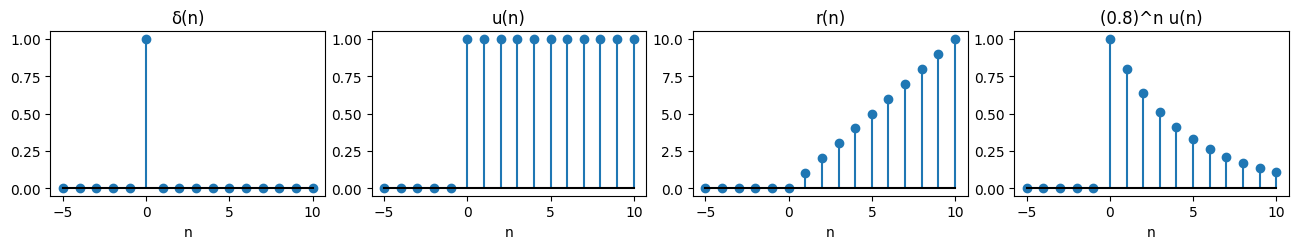

In [2]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

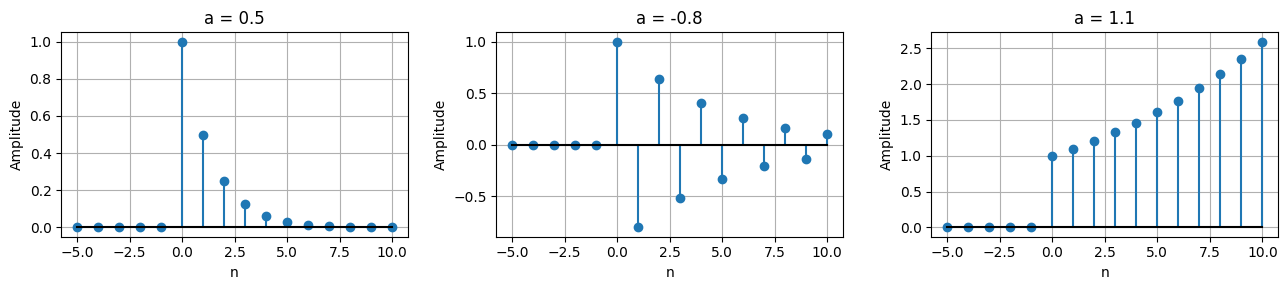

In [3]:
n = np.arange(-5, 11)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a**n) * (n >= 0)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

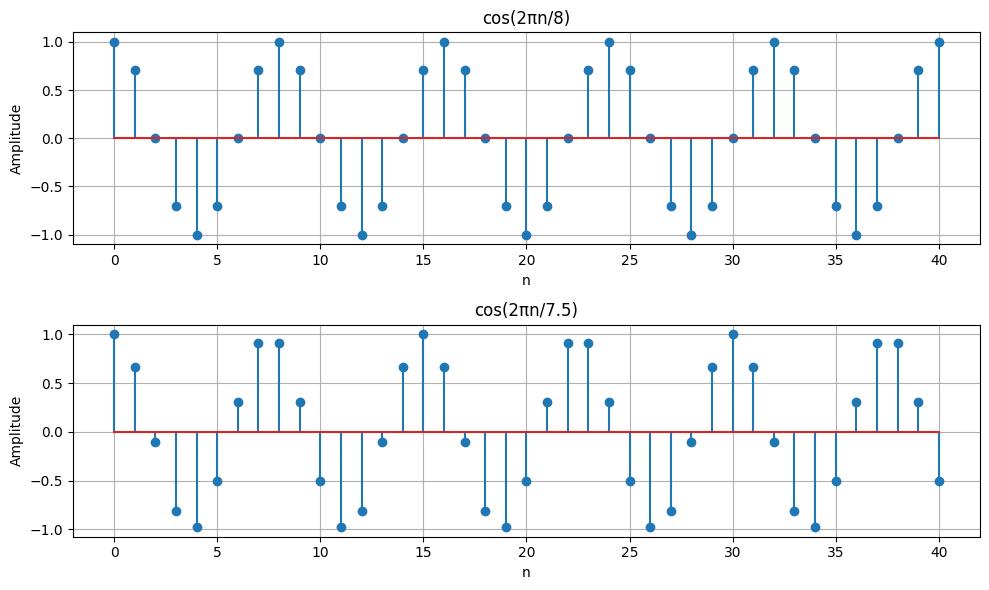

In [4]:
n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1295/3139354934.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  x, fs = librosa.load(fname, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Sampling frequency = 48000 Hz
Duration = 6.14 seconds
Number of samples = 294912


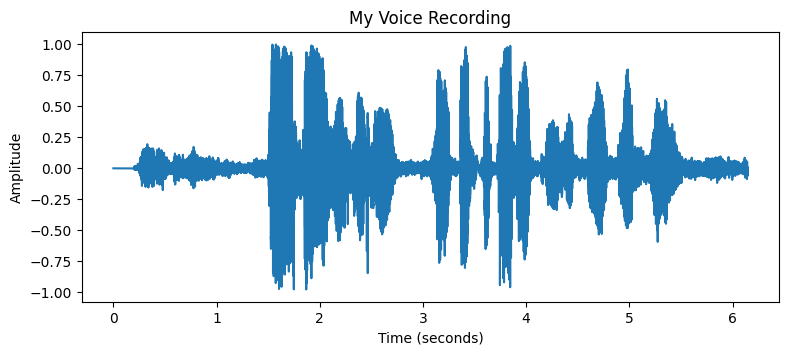

In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt

fname = "my_voice.wav"

if os.path.exists(fname):
    try:
        # Try using librosa to automatically decode various formats (MP4, M4A, WAV, etc.)
        import librosa
        # sr=None preserves the native sampling rate
        x, fs = librosa.load(fname, sr=None)
    except ImportError:
        # Fallback to soundfile if librosa is not installed
        try:
            import soundfile as sf
            x, fs = sf.read(fname)
            if x.ndim > 1:
                x = x.mean(axis=1)
        except Exception as e:
            print("Please install librosa or soundfile to load compressed audio formats:")
            print("!pip install librosa")
            raise e

    # Normalize the signal
    x = x / np.max(np.abs(x))

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs

print(f"Sampling frequency = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Number of samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.show()

In [26]:
from IPython.display import Audio

Audio(x, rate=fs)